In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

spark = SparkSession.builder.appName("Tugas14-KMeansMenu").master("local[*]").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
spark.conf.set("spark.sql.shuffle.partitions", "4")
print("SparkSession siap. Versi Spark:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/26 10:17:39 WARN Utils: Your hostname, vmi3356457, resolves to a loopback address: 127.0.1.1; using 13.140.149.59 instead (on interface eth0)
26/11/26 10:17:39 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/26 10:17:43 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/26 10:17:47 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


SparkSession siap. Versi Spark: 4.2.1


### Menyiapkan Dataset (dari modul)

In [2]:
np.random.seed(140)
n_menu = 60

pola_1 = pd.DataFrame({"harga": np.random.normal(18000, 2000, 20), "rata_rata_pesanan_harian": np.random.normal(45, 8, 20)})
pola_2 = pd.DataFrame({"harga": np.random.normal(45000, 5000, 20), "rata_rata_pesanan_harian": np.random.normal(8, 3, 20)})
pola_3 = pd.DataFrame({"harga": np.random.normal(28000, 3000, 20), "rata_rata_pesanan_harian": np.random.normal(22, 5, 20)})

data_tugas14 = pd.concat([pola_1, pola_2, pola_3], ignore_index=True)
data_tugas14["harga"] = data_tugas14["harga"].clip(lower=10000).round(-2)
data_tugas14["rata_rata_pesanan_harian"] = data_tugas14["rata_rata_pesanan_harian"].clip(lower=1).round(1)
data_tugas14["menu_id"] = [f"MENU-{i:03d}" for i in range(len(data_tugas14))]
data_tugas14 = data_tugas14.sample(frac=1, random_state=1).reset_index(drop=True)

data_tugas14.to_csv("tugas14_menu.csv", index=False)
print(f"Dataset berhasil dibuat: {len(data_tugas14)} menu")
print(data_tugas14.head())

Dataset berhasil dibuat: 60 menu
     harga  rata_rata_pesanan_harian   menu_id
0  40000.0                       9.4  MENU-039
1  31000.0                      15.3  MENU-041
2  18400.0                      62.9  MENU-002
3  30500.0                      24.8  MENU-048
4  26500.0                      25.9  MENU-050


### Membaca CSV ke Spark
Path dibuat absolut dengan skema `file://` karena CSV ditulis pandas ke disk **lokal**, sedangkan path relatif akan dicari Spark di HDFS jika `fs.defaultFS` mengarah ke HDFS.

In [3]:
path_csv = "file://" + os.path.abspath("tugas14_menu.csv")
df = spark.read.csv(path_csv, header=True, inferSchema=True)
df.printSchema()
print("Jumlah menu:", df.count())
df.show(5)

root
 |-- harga: double (nullable = true)
 |-- rata_rata_pesanan_harian: double (nullable = true)
 |-- menu_id: string (nullable = true)



Jumlah menu: 60
+-------+------------------------+--------+
|  harga|rata_rata_pesanan_harian| menu_id|
+-------+------------------------+--------+
|40000.0|                     9.4|MENU-039|
|31000.0|                    15.3|MENU-041|
|18400.0|                    62.9|MENU-002|
|30500.0|                    24.8|MENU-048|
|26500.0|                    25.9|MENU-050|
+-------+------------------------+--------+
only showing top 5 rows


## A. Feature Engineering

In [4]:
assembler = VectorAssembler(inputCols=["harga", "rata_rata_pesanan_harian"], outputCol="features_mentah")
df_assembled = assembler.transform(df)

scaler = StandardScaler(inputCol="features_mentah", outputCol="features", withStd=True, withMean=True)
scaler_model = scaler.fit(df_assembled)
df_scaled = scaler_model.transform(df_assembled)

df_scaled.select("menu_id", "harga", "rata_rata_pesanan_harian", "features").show(5, truncate=False)

+--------+-------+------------------------+--------------------------------------------+
|menu_id |harga  |rata_rata_pesanan_harian|features                                    |
+--------+-------+------------------------+--------------------------------------------+
|MENU-039|40000.0|9.4                     |[0.8697214695613823,-0.9787156001973806]    |
|MENU-041|31000.0|15.3                    |[0.08736332602790525,-0.6388437908292494]   |
|MENU-002|18400.0|62.9                    |[-1.0079380749189626,2.10317284068313]      |
|MENU-048|30500.0|24.8                    |[0.043898984720489864,-0.09159257235514]    |
|MENU-050|26500.0|25.9                    |[-0.30381574573883324,-0.028226641794980082]|
+--------+-------+------------------------+--------------------------------------------+
only showing top 5 rows


**Mengapa scaling diperlukan:** `harga` bernilai puluhan ribu rupiah sedangkan `rata_rata_pesanan_harian` hanya berkisar satu hingga puluhan, sehingga tanpa scaling jarak Euclidean pada K-Means akan didominasi `harga` dan pola popularitas menu nyaris diabaikan.

## B. Elbow Method (k = 2 sampai 6)

k=2  ->  WSSSE = 38.56  |  Silhouette = 0.7116
k=3  ->  WSSSE = 12.68  |  Silhouette = 0.8219
k=4  ->  WSSSE = 9.63  |  Silhouette = 0.7842
k=5  ->  WSSSE = 7.48  |  Silhouette = 0.6505
k=6  ->  WSSSE = 7.01  |  Silhouette = 0.6208


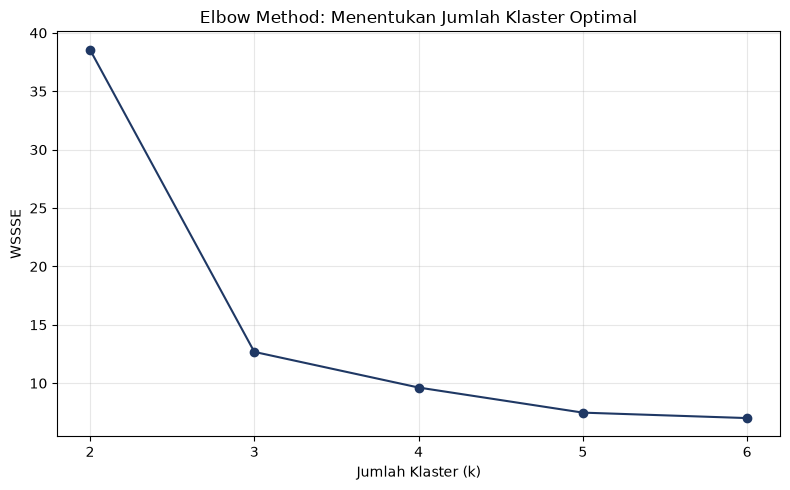

In [5]:
evaluator = ClusteringEvaluator(featuresCol="features")

hasil = []
for k in range(2, 7):
    m = KMeans(featuresCol="features", k=k, seed=42).fit(df_scaled)
    wssse = m.summary.trainingCost
    sil = evaluator.evaluate(m.transform(df_scaled))
    hasil.append((k, wssse, sil))
    print(f"k={k}  ->  WSSSE = {wssse:.2f}  |  Silhouette = {sil:.4f}")

k_list = [h[0] for h in hasil]
wssse_list = [h[1] for h in hasil]

plt.figure(figsize=(8, 5))
plt.plot(k_list, wssse_list, marker="o", color="#1F3864")
plt.title("Elbow Method: Menentukan Jumlah Klaster Optimal")
plt.xlabel("Jumlah Klaster (k)")
plt.ylabel("WSSSE")
plt.xticks(k_list)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Penentuan siku secara numerik: k dengan penurunan WSSSE yang paling "patah"
# (penurunan sebelum k dikurangi penurunan sesudah k, dicari yang terbesar).
w = dict(zip(k_list, wssse_list))
skor_siku = {k: (w[k-1] - w[k]) - (w[k] - w[k+1]) for k in range(3, 6)}
print("Skor kelengkungan siku per k:", {k: round(v, 2) for k, v in skor_siku.items()})

K_OPTIMAL = max(skor_siku, key=skor_siku.get)   # ubah manual di sini jika grafik Anda menunjukkan hal lain
print("k optimal yang dipilih:", K_OPTIMAL)

Skor kelengkungan siku per k: {3: 22.82, 4: 0.9, 5: 1.68}
k optimal yang dipilih: 3


**Pemilihan k:** *(isi setelah melihat grafik di atas, 1-2 kalimat)*. Contoh kerangka: "Penurunan WSSSE dari k=2 ke k=… sangat tajam, sedangkan setelahnya melandai sehingga siku berada di k=…; nilai Silhouette tertinggi juga/tidak berada di k yang sama, sehingga …"

## C. Melatih Model Final

In [7]:
kmeans_final = KMeans(featuresCol="features", k=K_OPTIMAL, seed=42)
model = kmeans_final.fit(df_scaled)
predictions = model.transform(df_scaled).withColumnRenamed("prediction", "klaster")

silhouette = ClusteringEvaluator(featuresCol="features", predictionCol="klaster").evaluate(predictions)
print(f"k = {K_OPTIMAL}")
print(f"Silhouette Score: {silhouette:.4f}")

print("\nJumlah menu per klaster:")
predictions.groupBy("klaster").count().orderBy("klaster").show()

k = 3
Silhouette Score: 0.8219

Jumlah menu per klaster:
+-------+-----+
|klaster|count|
+-------+-----+
|      0|   19|
|      1|   21|
|      2|   20|
+-------+-----+



## D. Interpretasi Bisnis

In [8]:
ringkasan = (predictions.groupBy("klaster")
             .agg(F.count("*").alias("jumlah_menu"),
                  F.round(F.avg("harga"), 0).alias("rata2_harga"),
                  F.round(F.avg("rata_rata_pesanan_harian"), 1).alias("rata2_pesanan_harian"))
             .orderBy("klaster"))
ringkasan.show()

rp = ringkasan.toPandas()

# Penamaan berbasis peringkat harga (klaster nomor 0/1/2 sendiri tidak bermakna).
nama_klaster = {int(r.klaster): f"Klaster {int(r.klaster)}" for r in rp.itertuples()}
if K_OPTIMAL == 3:
    id_murah = int(rp.loc[rp["rata2_harga"].idxmin(), "klaster"])
    id_mahal = int(rp.loc[rp["rata2_harga"].idxmax(), "klaster"])
    nama_klaster = {int(r.klaster): "Menu Menengah" for r in rp.itertuples()}
    nama_klaster[id_murah] = "Menu Andalan Terjangkau"
    nama_klaster[id_mahal] = "Menu Premium Jarang Dipesan"

    # Pemeriksaan: nama di atas mengasumsikan menu termurah = paling laris, termahal = paling jarang.
    id_laris = int(rp.loc[rp["rata2_pesanan_harian"].idxmax(), "klaster"])
    id_sepi = int(rp.loc[rp["rata2_pesanan_harian"].idxmin(), "klaster"])
    if id_laris != id_murah or id_sepi != id_mahal:
        print("PERINGATAN: urutan harga dan popularitas tidak searah, ubah nama klaster secara manual.")

print("\nProfil tiap klaster:")
for r in rp.itertuples():
    print(f"- Klaster {int(r.klaster)} -> {nama_klaster[int(r.klaster)]}: "
          f"{int(r.jumlah_menu)} menu, rata-rata harga Rp{r.rata2_harga:,.0f}, "
          f"rata-rata {r.rata2_pesanan_harian} pesanan/hari")

+-------+-----------+-----------+--------------------+
|klaster|jumlah_menu|rata2_harga|rata2_pesanan_harian|
+-------+-----------+-----------+--------------------+
|      0|         19|    44732.0|                 8.7|
|      1|         21|    28186.0|                22.0|
|      2|         20|    17895.0|                47.8|
+-------+-----------+-----------+--------------------+



/home/zhio/jupyter-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)



Profil tiap klaster:
- Klaster 0 -> Menu Premium Jarang Dipesan: 19 menu, rata-rata harga Rp44,732, rata-rata 8.7 pesanan/hari
- Klaster 1 -> Menu Menengah: 21 menu, rata-rata harga Rp28,186, rata-rata 22.0 pesanan/hari
- Klaster 2 -> Menu Andalan Terjangkau: 20 menu, rata-rata harga Rp17,895, rata-rata 47.8 pesanan/hari


**Alasan penamaan** *(lengkapi berdasarkan angka pada output di atas, satu kalimat per klaster)*:

- **Menu Andalan Terjangkau**: harga paling rendah (rata-rata Rp«...») namun paling sering dipesan («...» pesanan/hari), sehingga menjadi penarik traffic.
- **Menu Menengah**: harga dan popularitas berada di tengah (Rp«...», «...» pesanan/hari).
- **Menu Premium Jarang Dipesan**: harga paling tinggi (Rp«...») tetapi hanya «...» pesanan/hari, sehingga kontribusi volumenya kecil.

## E. Visualisasi Klaster

/home/zhio/jupyter-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


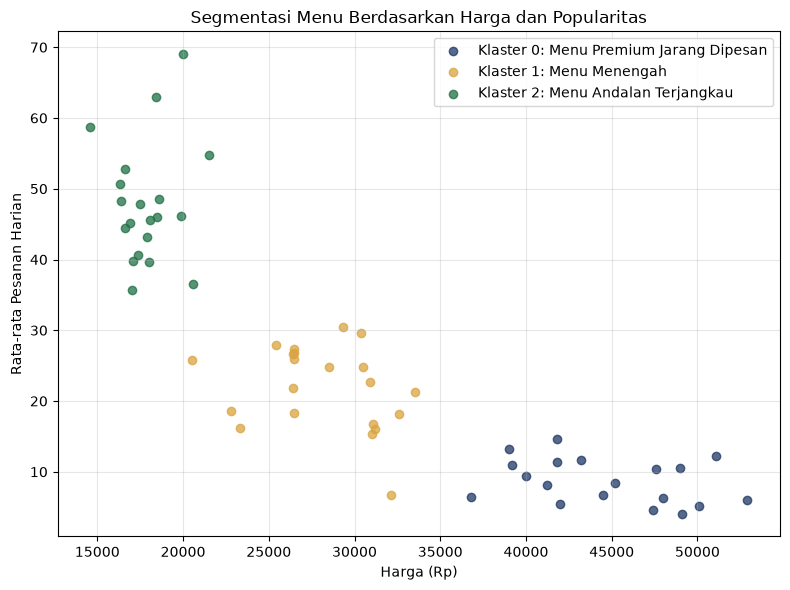

In [9]:
pdf_plot = predictions.select("menu_id", "harga", "rata_rata_pesanan_harian", "klaster").toPandas()  # aman: hanya 60 baris
warna = ["#1F3864", "#D9A441", "#1E7145", "#C0392B", "#7D3C98", "#117A8B"]

plt.figure(figsize=(8, 6))
for kl in sorted(pdf_plot["klaster"].unique()):
    sub = pdf_plot[pdf_plot["klaster"] == kl]
    plt.scatter(sub["harga"], sub["rata_rata_pesanan_harian"],
                label=f"Klaster {kl}: {nama_klaster[kl]}", color=warna[kl % len(warna)], alpha=0.75)

plt.title("Segmentasi Menu Berdasarkan Harga dan Popularitas")
plt.xlabel("Harga (Rp)")
plt.ylabel("Rata-rata Pesanan Harian")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## F. Rekomendasi Bundling

> *Petunjuk: angka bertanda «...» isi dari output bagian D, lalu hapus petunjuk ini.*

**Usulan paket: "Paket Hemat Premium"**, yaitu satu **Menu Andalan Terjangkau** digabung dengan satu **Menu Premium Jarang Dipesan** dengan potongan harga paket yang kecil. Menu andalan rata-rata dipesan «...» kali per hari sehingga sudah memiliki arus pelanggan yang stabil, sedangkan menu premium hanya «...» kali per hari dan butuh paparan tambahan. Dengan menempelkan menu premium pada menu yang sudah laris, pelanggan mencoba menu premium tanpa harus memutuskan sendiri membayar lebih mahal, sehingga volume menu premium naik tanpa perlu iklan terpisah. Potongan harga sebaiknya dihitung dari margin masing-masing menu (data margin tidak ada pada dataset ini), agar paket tidak menggerus keuntungan. Efektivitasnya perlu diukur dengan membandingkan pesanan harian menu premium sebelum dan sesudah paket diluncurkan.

In [10]:
spark.stop()
print("SparkSession ditutup.")

SparkSession ditutup.
